In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import climate_indices as clindices
from tqdm import tqdm

from climate_indices.typed_public_api import (
    spi,
    spei,
    pet_thornthwaite
)

from climate_indices import compute

In [33]:
# Read in the csv generated by the csv
scarriff = pd.read_csv('DATA/CatchmentTimeSeries/SCARRIFF_allvars.csv')#, date_format='%Y-%m-%d')
scarriff.Date = pd.to_datetime(scarriff.Date, format='%Y-%m-%d')
curranure = pd.read_csv('DATA/CatchmentTimeSeries/CURRANURE_allvars.csv')
curranure.Date = pd.to_datetime(curranure.Date, format='%Y-%m-%d')
ballysadare = pd.read_csv('DATA/CatchmentTimeSeries/BALLYSADARE_allvars.csv')
ballysadare.Date = pd.to_datetime(ballysadare.Date, format='%Y-%m-%d')
leixlip = pd.read_csv('DATA/CatchmentTimeSeries/LEIXLIP_allvars.csv')
leixlip.Date = pd.to_datetime(leixlip.Date, format='%Y-%m-%d')

print(scarriff.isna().sum())
print(curranure.isna().sum())
print(ballysadare.isna().sum())
print(leixlip.isna().sum())

scarriff.info()

Date        0
Rainfall    0
MeanTemp    0
MaxTemp     0
MinTemp     0
dtype: int64
Date        0
Rainfall    0
MeanTemp    0
MaxTemp     0
MinTemp     0
dtype: int64
Date        0
Rainfall    0
MeanTemp    0
MaxTemp     0
MinTemp     0
dtype: int64
Date        0
Rainfall    0
MeanTemp    0
MaxTemp     0
MinTemp     0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      360 non-null    datetime64[us]
 1   Rainfall  360 non-null    float64       
 2   MeanTemp  360 non-null    float64       
 3   MaxTemp   360 non-null    float64       
 4   MinTemp   360 non-null    float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 14.2 KB


Text(0.5, 1.0, 'Mean monthly quantities, averaged over catchment area')

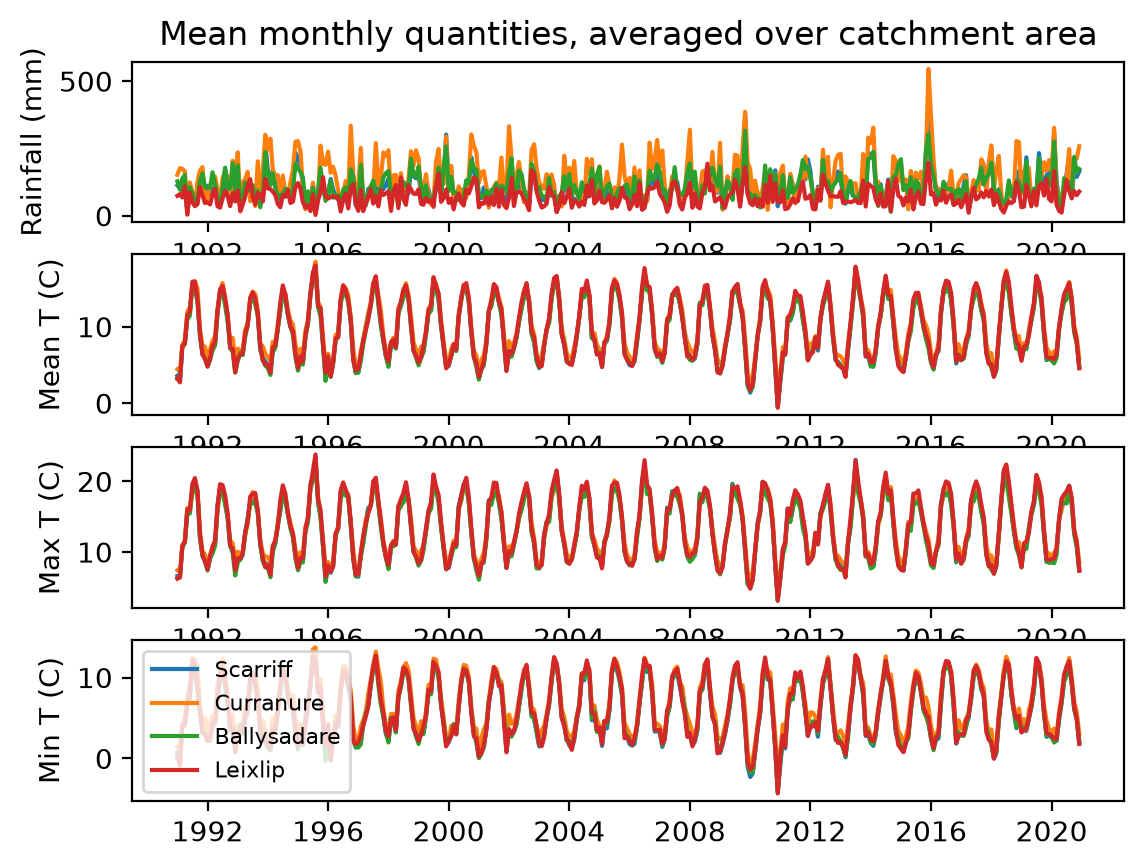

In [25]:
fig, ax = plt.subplots(4,1, dpi=200)

ax[0].plot(scarriff['Date'], scarriff['Rainfall'])
ax[0].plot(curranure['Date'], curranure['Rainfall'])
ax[0].plot(ballysadare['Date'], ballysadare['Rainfall'])
ax[0].plot(leixlip['Date'], leixlip['Rainfall'])

ax[1].plot(scarriff['Date'], scarriff['MeanTemp'])
ax[1].plot(curranure['Date'], curranure['MeanTemp'])
ax[1].plot(ballysadare['Date'], ballysadare['MeanTemp'])
ax[1].plot(leixlip['Date'], leixlip['MeanTemp'])

ax[2].plot(scarriff['Date'], scarriff['MaxTemp'])
ax[2].plot(curranure['Date'], curranure['MaxTemp'])
ax[2].plot(ballysadare['Date'], ballysadare['MaxTemp'])
ax[2].plot(leixlip['Date'], leixlip['MaxTemp'])

ax[3].plot(scarriff['Date'], scarriff['MinTemp'])
ax[3].plot(curranure['Date'], curranure['MinTemp'])
ax[3].plot(ballysadare['Date'], ballysadare['MinTemp'])
ax[3].plot(leixlip['Date'], leixlip['MinTemp'])

ax[3].legend(['Scarriff', 'Curranure', 'Ballysadare', 'Leixlip'], fontsize=8)
ax[0].set_ylabel('Rainfall (mm)')
ax[1].set_ylabel('Mean T (C)')
ax[2].set_ylabel('Max T (C)')
ax[3].set_ylabel('Min T (C)')
ax[0].set_title('Mean monthly quantities, averaged over catchment area')

## Calculate the climate indices

In [32]:
spi_3_sc = spi(
    values=scarriff[[ 'Rainfall']].to_numpy(),
    scale=3,
    distribution=compute.Distribution.gamma,
    data_start_year=1991,
    calibration_year_initial=1991,
    calibration_year_final=2020,
    periodicity=compute.Periodicity.monthly
)

2026-11-16T15:26:12.172468Z [info     ] calculation_started            [climate_indices.indices] distribution=gamma index_type=spi input_elements=360 input_shape=(360, 1) output_scale=normal scale=3
2026-11-16T15:26:12.174761Z [info     ] distribution_fitting_started   [climate_indices.compute] calibration_period=1991-2020 distribution=gamma operation=gamma_parameters periodicity=monthly
2026-11-16T15:26:12.196004Z [info     ] distribution_fitting_completed [climate_indices.compute] calibration_period=1991-2020 distribution=gamma operation=gamma_parameters output_shape=(12,) periodicity=monthly
2026-11-16T15:26:12.197342Z [info     ] distribution_transform_started [climate_indices.compute] distribution=gamma input_shape='(30, 12)' operation=transform_fitted_gamma output_scale=normal periodicity=monthly
2026-11-16T15:26:12.199503Z [info     ] distribution_transform_completed [climate_indices.compute] distribution=gamma input_shape='(30, 12)' operation=transform_fitted_gamma output_scale

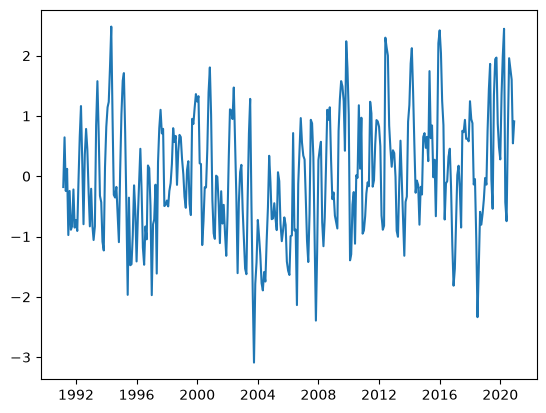

In [35]:
plt.plot(scarriff.Date, spi_3_sc)

In [47]:
windows = [1, 3, 6, 12]

indices_df_sc = pd.DataFrame({'Date':scarriff.Date})

for window in windows:

    indices_df_sc[f"SPI_{window}"] = spi(
        values=scarriff[[ 'Rainfall']].to_numpy(),
        scale=window,
        distribution=compute.Distribution.gamma,
        data_start_year=1991,
        calibration_year_initial=1991,
        calibration_year_final=2020,
        periodicity=compute.Periodicity.monthly
    )
# TODO: I think this is working well but I want to ultimately have a df for each catchment with all indices
# So before looping over every catchment here get all indices up and running

2026-11-16T15:40:50.262966Z [info     ] calculation_started            [climate_indices.indices] distribution=gamma index_type=spi input_elements=360 input_shape=(360, 1) output_scale=normal scale=1
2026-11-16T15:40:50.265230Z [info     ] distribution_fitting_started   [climate_indices.compute] calibration_period=1991-2020 distribution=gamma operation=gamma_parameters periodicity=monthly
2026-11-16T15:40:50.268034Z [info     ] distribution_fitting_completed [climate_indices.compute] calibration_period=1991-2020 distribution=gamma operation=gamma_parameters output_shape=(12,) periodicity=monthly
2026-11-16T15:40:50.269656Z [info     ] distribution_transform_started [climate_indices.compute] distribution=gamma input_shape='(30, 12)' operation=transform_fitted_gamma output_scale=normal periodicity=monthly
2026-11-16T15:40:50.271973Z [info     ] distribution_transform_completed [climate_indices.compute] distribution=gamma input_shape='(30, 12)' operation=transform_fitted_gamma output_scale

In [48]:
# Chek out PET
# Using the Thornthwaite version because I don't have daily data including in the dataset for Samani
temperature = scarriff["MeanTemp"].to_numpy()

pet = pet_thornthwaite(
    temperature=temperature,
    latitude=52.55,
    data_start_year=1991
)

indices_df_sc["PET"] = pet

2026-11-16T15:40:51.400313Z [info     ] calculation_started            [climate_indices.indices] index_type=pet_thornthwaite input_elements=360 input_shape=(360,)
2026-11-16T15:40:51.431465Z [info     ] calculation_completed          [climate_indices.indices] duration_ms=29.93 index_type=pet_thornthwaite input_elements=360 input_shape=(360,) output_shape=(360,)


In [50]:
indices_df_sc.head(14)

,Date,SPI_1,SPI_3,SPI_6,SPI_12,PET
0,1991-01-01,-0.264322,NaN,NaN,NaN,11.599387
1,1991-02-01,0.103221,NaN,NaN,NaN,11.052289
2,1991-03-01,0.163367,-0.179059,NaN,NaN,35.829314
3,1991-04-01,1.279550,0.644806,NaN,NaN,43.591998
4,1991-05-01,-2.825749,-0.244461,NaN,NaN,75.152029
5,1991-06-01,0.624713,0.122440,-0.162529,NaN,80.685591
6,1991-07-01,-0.330893,-0.974997,-0.104894,NaN,106.790745
7,1991-08-01,-0.523484,-0.243611,-0.411584,NaN,97.789800
8,1991-09-01,-0.317155,-0.887516,-0.665093,NaN,70.717383
9,1991-10-01,-0.204426,-0.826546,-1.371532,NaN,38.419569
